In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

## 1. Data Loading and Exploratory Data Analysis (EDA)

### Data Loading

In [2]:
df = pd.read_csv('CC GENERAL.csv')

### Exploratory Data Analysis (EDA)

#### Initial Dataset Information

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

#### Showing the first 5 rows of the dataset

In [4]:
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


#### Showing how many null values the dataset has per column.

In [5]:
df.isna().sum()

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

#### Dataset dimensions (rows, columns)

In [6]:
df.shape

(8950, 18)

#### Descriptive statistics

In [7]:
df.describe().round(2)

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8949.00,8950.00,8637.00,8950.00,8950.00
mean,1564.47,0.88,1003.20,592.44,411.07,978.87,0.49,0.20,0.36,0.14,3.25,14.71,4494.45,1733.14,864.21,0.15,11.52
std,2081.53,0.24,2136.63,1659.89,904.34,2097.16,0.40,0.30,0.40,0.20,6.82,24.86,3638.82,2895.06,2372.45,0.29,1.34
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,50.00,0.00,0.02,0.00,6.00
25%,128.28,0.89,39.64,0.00,0.00,0.00,0.08,0.00,0.00,0.00,0.00,1.00,1600.00,383.28,169.12,0.00,12.00
50%,873.39,1.00,361.28,38.00,89.00,0.00,0.50,0.08,0.17,0.00,0.00,7.00,3000.00,856.90,312.34,0.00,12.00
75%,2054.14,1.00,1110.13,577.40,468.64,1113.82,0.92,0.30,0.75,0.22,4.00,17.00,6500.00,1901.13,825.49,0.14,12.00
max,19043.14,1.00,49039.57,40761.25,22500.00,47137.21,1.00,1.00,1.00,1.50,123.00,358.00,30000.00,50721.48,76406.21,1.00,12.00


#### Showing Outliers per Column

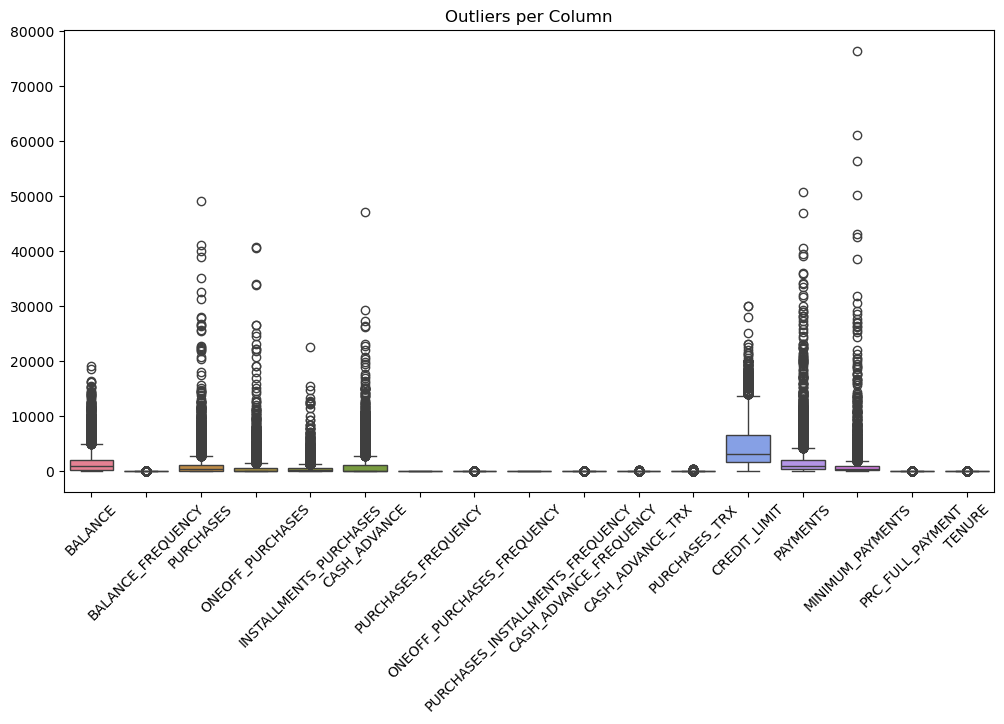

In [8]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.select_dtypes(include='number'))
plt.xticks(rotation=45)
plt.title('Outliers per Column')
plt.show()

## 2. Data Preprocessing

#### Removing CUST_ID from dataset in order to build the ML model

In [9]:
X = df.drop('CUST_ID', axis=1)

#### Using '.median()' to fill in the null values with the median of existing values in each column that has null values

In [10]:
X['MINIMUM_PAYMENTS'] = X['MINIMUM_PAYMENTS'].fillna(X['MINIMUM_PAYMENTS'].median())
X['CREDIT_LIMIT'] = X['CREDIT_LIMIT'].fillna(X['CREDIT_LIMIT'].median())

#### Defining financial columns for log transformation

In [11]:
financial_cols = [
    'BALANCE', 
    'PURCHASES', 
    'ONEOFF_PURCHASES', 
    'INSTALLMENTS_PURCHASES', 
    'CASH_ADVANCE', 
    'CREDIT_LIMIT', 
    'PAYMENTS', 
    'MINIMUM_PAYMENTS'
]

#### Applying log1p transformation to financial features

In [12]:
X[financial_cols] = np.log1p(X[financial_cols])

#### Scaling all features using StandardScaler

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#### Converting into a df to inspect outliers per column and proceeding with the process

In [14]:
X_final = pd.DataFrame(X_scaled, columns=X.columns)

In [15]:
X_final.isna().sum()

BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64

#### Showing Outliers per Column after Transformations

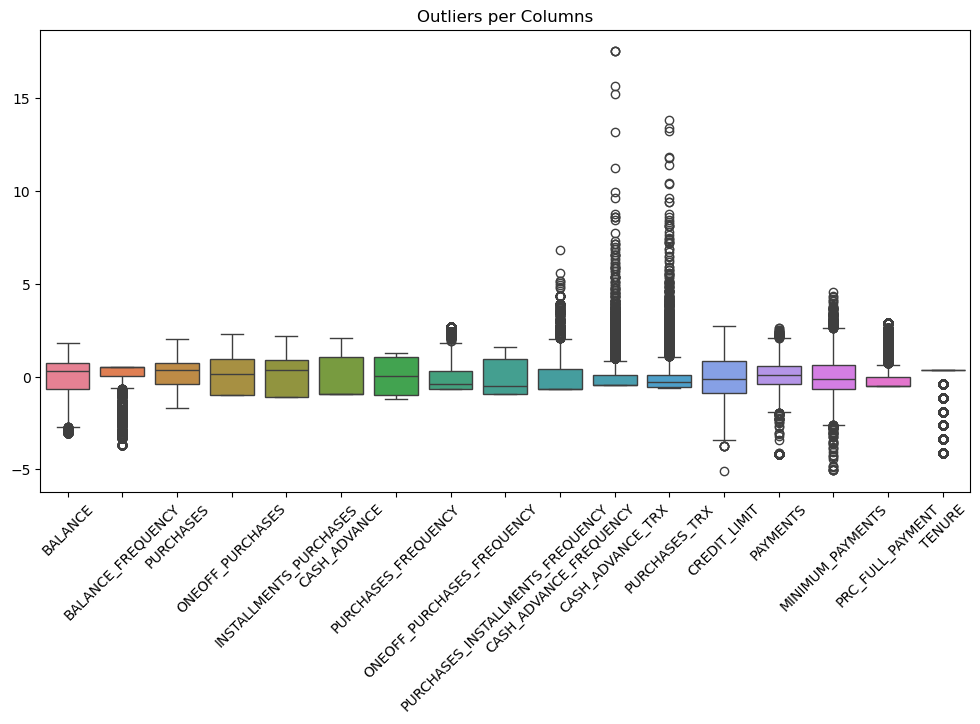

In [16]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_final.select_dtypes(include='number'))
plt.xticks(rotation=45)
plt.title('Outliers per Columns')
plt.show()

## 3. Determining optimal K (Elbow and Silhouette)

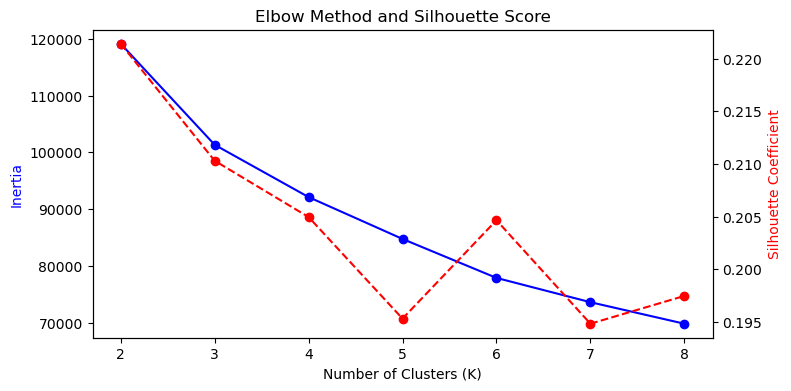

In [17]:
inertias = []
silhouettes = []
k_range = range(2, 9)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_final)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_final, labels))

fig, ax1 = plt.subplots(figsize=(8, 4))

ax1.plot(k_range, inertias, 'bo-', label='Inertia (WCSS)')
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia', color='b')

ax2 = ax1.twinx()
ax2.plot(k_range, silhouettes, 'ro--', label='Silhouette Score')
ax2.set_ylabel('Silhouette Coefficient', color='r')

plt.title('Elbow Method and Silhouette Score')
plt.show()

## 4. Training the final model with K = 3

In [18]:
K = 3
kmeans_final = KMeans(n_clusters=K, random_state=42, n_init=10)

df['Cluster'] = kmeans_final.fit_predict(X_final)

## 5. Dimensionality reduction with PCA

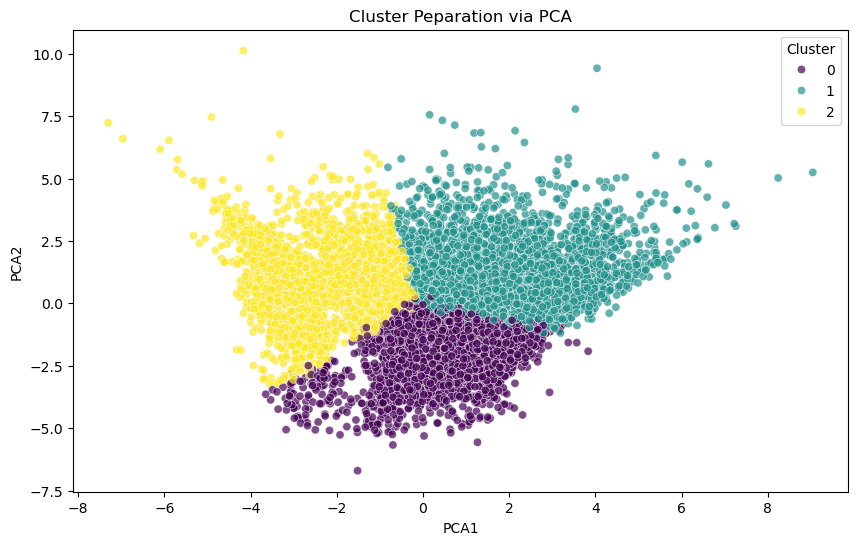

In [19]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X_final)
df['PCA1'] = coords[:, 0]
df['PCA2'] = coords[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', data=df, palette='viridis', alpha=0.7)
plt.title('Cluster Peparation via PCA')
plt.show()

## 6 Final Evaluation

#### Percentage of Customers per Cluster

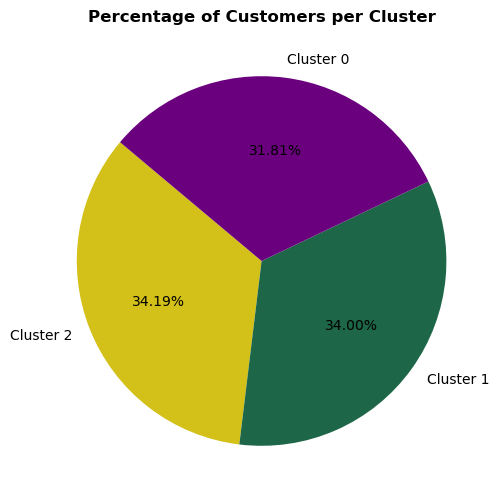

In [20]:
cluster_counts = df['Cluster'].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 6))
plt.pie(
    cluster_counts, 
    labels=[f'Cluster {i}' for i in cluster_counts.index], 
    autopct='%1.2f%%',
    startangle=140,
    colors=['#d3c11a', '#1e6648', '#6b007e']
)

plt.title('Percentage of Customers per Cluster', fontsize=12, fontweight='bold')
plt.show()

#### Financial Profile Summary per Cluster

In [21]:
cluster_summary = df.groupby('Cluster').mean(numeric_only=True)
print(cluster_summary[['BALANCE', 'PURCHASES', 'CREDIT_LIMIT', 'PAYMENTS', 'CASH_ADVANCE']])

             BALANCE    PURCHASES  CREDIT_LIMIT     PAYMENTS  CASH_ADVANCE
Cluster                                                                   
0         195.871649   463.488205   3274.699223   684.955085     55.188074
1        2018.752988  2373.433336   5820.559622  2658.603053    700.565755
2        2386.058098   142.736830   4310.153991  1788.052699   2115.017783


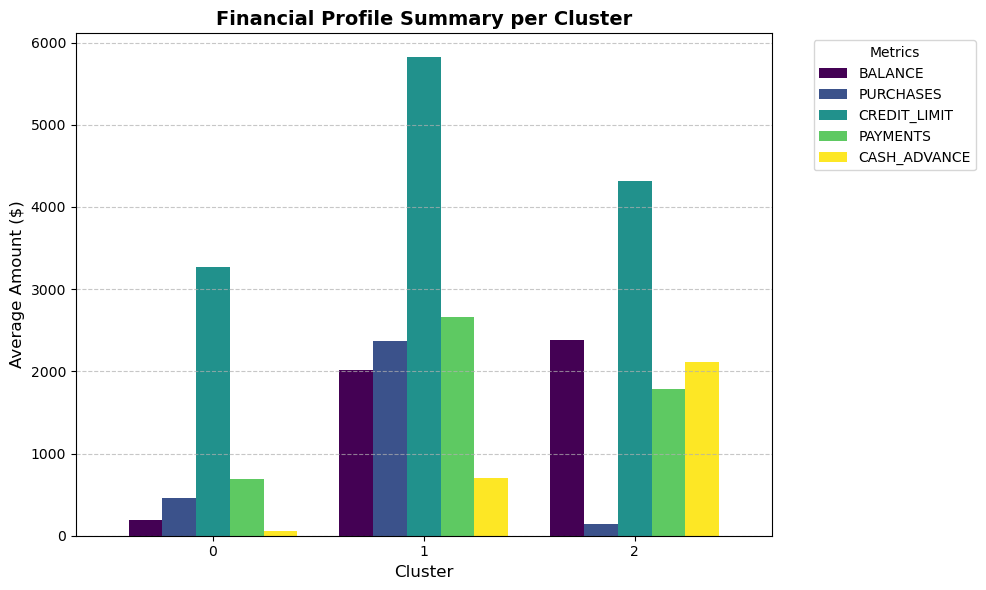

In [22]:
features = ['BALANCE', 'PURCHASES', 'CREDIT_LIMIT', 'PAYMENTS', 'CASH_ADVANCE']
cluster_summary = df.groupby('Cluster')[features].mean()

ax = cluster_summary.plot(kind='bar', figsize=(10, 6), colormap='viridis', width=0.8)

plt.title('Financial Profile Summary per Cluster', fontsize=14, fontweight='bold')
plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Average Amount ($)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Metrics', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

## Final feedback

### 🎯 Objective & Methodology
The goal of this project was to perform **Customer Segmentation** using Unsupervised Machine Learning (K-Means) on credit card usage data. 

To achieve optimal cluster separation, the data underwent missing value imputation, log transformation (log1p), and standardization (StandardScaler). Based on the **Elbow Method** and **Silhouette Analysis**, **K = 3** was selected as the optimal number of clusters, balancing mathematical separation with business interpretability.

### 📊 Key Cluster Profiles

1. **Cluster 0 — Occasional / Low-Usage Users (31.81%)**
   * **Behavior:** Low average balance (196) and purchases (463) with minimal cash advance activity.
   * **Strategy:** Drive engagement through loyalty programs, rewards, and cashback incentives to increase card usage.

2. **Cluster 1 — VIP / High-Value Buyers (34.00%)**
   * **Behavior:** Highest average purchases (2,373), highest credit limits (5,821), and consistent payments (2,659).
   * **Strategy:** High-value retention, premium card upgrades (e.g., Platinum/Black), and proactive limit extensions.

3. **Cluster 2 — Cash Advance / Debt Refinancers (34.19%)**
   * **Behavior:** Highest average balance (2,386) and massive cash advance usage (2,115), with almost no retail purchases (143).
   * **Strategy:** High risk of default. Offer personal loan refinancing products with lower interest rates to convert high-risk revolver debt into structured payments.

### 💡 Final Business Conclusion
The segmentation successfully isolated three distinct financial personas. Utilizing **K=3** provides the business with an actionable roadmap to tailor marketing campaigns, manage credit risk, and maximize customer lifetime value effectively.